# 2. Disparo no lineal: secante y Newton

Problema de contorno en $[a, b]$:

$$
y'' = f(x, y, y'), \qquad
\alpha_1\, y(a) + \beta_1\, y'(a) = \gamma_1, \qquad
\alpha_2\, y(b) + \beta_2\, y'(b) = \gamma_2 .
$$

Usamos los mismos datos iniciales que en el disparo lineal (cuaderno 1):
$y(a) = t$ si $\beta_1 \neq 0$, o $y'(a) = t$ si $\beta_1 = 0$. La ecuación
del disparo sigue siendo

$$
F(t) = \alpha_2\, y(b; t) + \beta_2\, y'(b; t) - \gamma_2 = 0,
$$

pero ahora $F$ **no es afín**: la superposición ya no sirve y tenemos que
resolver $F(t) = 0$ de forma iterativa. Cada evaluación de $F$ es un
problema de valor inicial que resolvemos con RK4.

## Método de la secante

Partimos de dos valores $t_0, t_1$ y aplicamos

$$
t_{k+1} = t_k - F(t_k)\,\frac{t_k - t_{k-1}}{F(t_k) - F(t_{k-1})},
$$

hasta que $|F(t_k)| < \text{tol}$. No necesita derivadas, pero converge con
orden $\frac{1 + \sqrt 5}{2} \approx 1.618$.

## Método de Newton

$$
t_{k+1} = t_k - \frac{F(t_k)}{F'(t_k)} .
$$

Para obtener $F'(t)$ derivamos respecto de $t$. Si llamamos
$z(x) = \partial y(x; t) / \partial t$, la regla de la cadena aplicada a
$y'' = f(x, y, y')$ da la **ecuación variacional**

$$
z'' = \frac{\partial f}{\partial y}(x, y, y')\, z
+ \frac{\partial f}{\partial y'}(x, y, y')\, z',
$$

con datos iniciales $\left(z(a), z'(a)\right) = (1, -\alpha_1/\beta_1)$ si
$\beta_1 \neq 0$, o $(0, 1)$ si $\beta_1 = 0$. Entonces

$$
F'(t) = \alpha_2\, z(b) + \beta_2\, z'(b) .
$$

En cada iteración integramos a la vez el sistema de 4 ecuaciones para
$(y, y', z, z')$. Newton converge con orden 2 si la raíz es simple.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from bvp import Robin, dirichlet, newton_shooting, secant_shooting

In [2]:
from IPython.display import Markdown, display


def table(headers, rows, fmt="{:.6g}"):
    """Show rows as a Markdown table."""
    def cell(v):
        return fmt.format(v) if isinstance(v, float) else str(v)

    lines = ["| " + " | ".join(headers) + " |",
             "|" + "---:|" * len(headers)]
    lines += ["| " + " | ".join(cell(v) for v in row) + " |"
              for row in rows]
    display(Markdown("\n".join(lines)))

In [3]:
def show_history(res, limit=None):
    rows = [(k, f"{t:.10f}", f"{F:.3e}")
            for k, (t, F) in enumerate(res.history)]
    if limit is not None and len(rows) > limit:
        rows = rows[:limit] + [("...", "...", "...")]
    table(["$k$", "$t_k$", "$F(t_k)$"], rows)

## Ejemplo 1: condiciones de Dirichlet

Ejemplo clásico de Burden y Faires:

$$
y'' = \frac{1}{8}\left(32 + 2x^3 - y\, y'\right), \qquad x \in [1, 3],
\qquad y(1) = 17, \quad y(3) = \frac{43}{3},
$$

con solución exacta $y = x^2 + 16/x$. Como $\beta_1 = 0$, disparamos con la
pendiente: $t = y'(1)$ (el valor exacto es $t^\ast = -14$).

Las derivadas parciales para Newton son

$$
\frac{\partial f}{\partial y} = -\frac{y'}{8}, \qquad
\frac{\partial f}{\partial y'} = -\frac{y}{8} .
$$

In [4]:
def f1(x, y, dy):
    return (32 + 2 * x**3 - y * dy) / 8


def f1_y(x, y, dy):
    return -dy / 8


def f1_dy(x, y, dy):
    return -y / 8


left1, right1 = dirichlet(17), dirichlet(43 / 3)
sec1 = secant_shooting(f1, 1, 3, left1, right1, t0=-4 / 3, t1=-1, n=20)
newt1 = newton_shooting(f1, f1_y, f1_dy, 1, 3, left1, right1, t0=-4 / 3,
                        n=20)

**Secante** ($t_0 = -4/3$, $t_1 = -1$):

In [5]:
show_history(sec1)

| $k$ | $t_k$ | $F(t_k)$ |
|---:|---:|---:|
| 0 | -1.3333333333 | 6.146e+00 |
| 1 | -1.0000000000 | 6.282e+00 |
| 2 | -16.3706850477 | -1.462e+00 |
| 3 | -13.4687623885 | 3.094e-01 |
| 4 | -13.9755625092 | 1.448e-02 |
| 5 | -14.0004402680 | -1.460e-04 |
| 6 | -14.0001918003 | 6.868e-08 |

**Newton** ($t_0 = -4/3$):

In [6]:
show_history(newt1)

| $k$ | $t_k$ | $F(t_k)$ |
|---:|---:|---:|
| 0 | -1.3333333333 | 6.146e+00 |
| 1 | -16.3175826768 | -1.428e+00 |
| 2 | -14.1087451417 | -6.396e-02 |
| 3 | -14.0004175912 | -1.327e-04 |
| 4 | -14.0001919180 | -5.720e-10 |

In [7]:
for name, res in [("secante", sec1), ("Newton", newt1)]:
    err = np.max(np.abs(res.y - (res.x**2 + 16 / res.x)))
    print(f"{name:8s} iteraciones = {res.iterations}, "
          f"error máximo = {err:.2e}")

secante  iteraciones = 5, error máximo = 6.20e-05
Newton   iteraciones = 4, error máximo = 6.20e-05


## Ejemplo 2: condiciones de Robin

$$
y'' = -\left(y'\right)^2, \qquad x \in [0, 1], \qquad
y(0) + y'(0) = 1, \quad y(1) - y'(1) = \ln 2 - \frac{1}{2},
$$

con solución exacta $y = \ln(1 + x)$. Ahora $\beta_1 = 1$, así que
$t = y(0)$ e $y'(0) = 1 - t$ (el valor exacto es $t^\ast = 0$).

Este ejemplo admite $F(t)$ en forma cerrada. La solución general es
$y = \ln|x + c| + d$, y con $y(0) = t$, $y'(0) = 1 - t$ se obtiene, para
$t < 2$,

$$
y(1; t) = t + \ln(2 - t), \qquad y'(1; t) = \frac{1 - t}{2 - t},
\qquad
F(t) = t + \ln(2 - t) - \frac{1 - t}{2 - t} - \ln 2 + \frac{1}{2} .
$$

Con $s = 1/(2 - t) > 0$ queda $F'(t) = (1 - s) + s^2 > 0$: $F$ es
estrictamente creciente y la solución es **única**.

Las derivadas parciales son

$$
\frac{\partial f}{\partial y} = 0, \qquad
\frac{\partial f}{\partial y'} = -2\, y' .
$$

In [8]:
def f2(x, y, dy):
    return -dy**2


def f2_y(x, y, dy):
    return 0.0


def f2_dy(x, y, dy):
    return -2 * dy


left2 = Robin(1, 1, 1)
right2 = Robin(1, -1, np.log(2) - 0.5)
sec2 = secant_shooting(f2, 0, 1, left2, right2, t0=1.0, t1=0.8, n=10,
                       tol=1e-10)
newt2 = newton_shooting(f2, f2_y, f2_dy, 0, 1, left2, right2, t0=1.0,
                        n=10, tol=1e-10)

**Secante** ($t_0 = 1$, $t_1 = 0.8$):

In [9]:
show_history(sec2)

| $k$ | $t_k$ | $F(t_k)$ |
|---:|---:|---:|
| 0 | 1.0000000000 | 8.069e-01 |
| 1 | 0.8000000000 | 6.225e-01 |
| 2 | 0.1246279190 | 9.351e-02 |
| 3 | 0.0052371983 | 3.926e-03 |
| 4 | 0.0000051082 | 1.935e-06 |
| 5 | 0.0000025275 | 1.321e-12 |

**Newton** ($t_0 = 1$). Fíjate en cómo $|F(t_k)|$ pasa a tener
aproximadamente el doble de ceros en cada paso al final: es la convergencia
cuadrática.

In [10]:
show_history(newt2)

| $k$ | $t_k$ | $F(t_k)$ |
|---:|---:|---:|
| 0 | 1.0000000000 | 8.069e-01 |
| 1 | 0.1931471806 | 1.450e-01 |
| 2 | 0.0005029443 | 3.753e-04 |
| 3 | 0.0000025275 | 2.276e-12 |

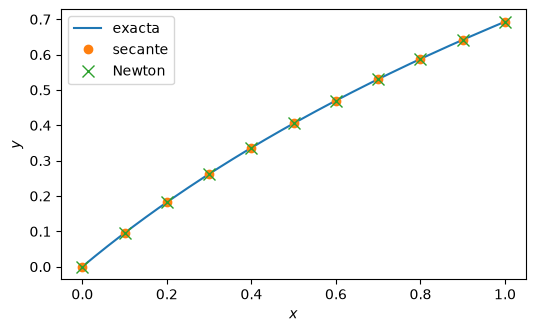

secante  t = 2.528e-06, error máximo = 2.53e-06
Newton   t = 2.528e-06, error máximo = 2.53e-06


In [11]:
xs = np.linspace(0, 1, 200)
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(xs, np.log1p(xs), label="exacta")
ax.plot(sec2.x, sec2.y, "o", label="secante")
ax.plot(newt2.x, newt2.y, "x", ms=9, label="Newton")
ax.set_xlabel("$x$")
ax.set_ylabel("$y$")
ax.legend()
plt.show()

for name, res in [("secante", sec2), ("Newton", newt2)]:
    err = np.max(np.abs(res.y - np.log1p(res.x)))
    print(f"{name:8s} t = {res.t:.3e}, error máximo = {err:.2e}")

El último $t$ no es exactamente $0$: buscamos la raíz de la $F$ **discreta**
(calculada con RK4 y $N = 10$), que difiere de la exacta en el error de
discretización, del orden de $10^{-6}$.

## Cuidado: raíces dobles

Si cambiamos la condición derecha por $y(1) + 2\, y'(1) = 1 + \ln 2$, la
solución exacta sigue siendo $\ln(1 + x)$, pero ahora $F'(t^\ast) = 0$: la
raíz es **doble**. Lo comprobamos a mano: con $y = \ln(x + c) + d$,
$c = 1/(1 - t)$, resulta

$$
F'(0) = \frac{1}{2} - \frac{\beta_2}{4},
$$

que se anula para $\beta_2 = 2$. Newton pierde la convergencia cuadrática:
en la tabla, $t_k$ se reduce aproximadamente a la mitad en cada paso
(convergencia lineal). Además, la raíz está mal condicionada: la $F$
discreta (RK4, $N = 10$) no llega a anularse, porque su máximo cerca de
$t = 0$ es negativo, del orden de $-10^{-6}$. Por eso Newton deja de
avanzar y oscila sin alcanzar la tolerancia.

In [12]:
right_double = Robin(1, 2, 1 + np.log(2))
newt_double = newton_shooting(f2, f2_y, f2_dy, 0, 1, left2, right_double,
                              t0=1.0, n=10, tol=1e-10)
print(f"convergió: {newt_double.converged}, "
      f"iteraciones: {newt_double.iterations}, t = {newt_double.t:.3e}")
show_history(newt_double, limit=15)

convergió: False, iteraciones: 50, t = 2.965e-03


| $k$ | $t_k$ | $F(t_k)$ |
|---:|---:|---:|
| 0 | 1.0000000000 | -6.931e-01 |
| 1 | 0.6534264097 | -2.274e-01 |
| 2 | 0.3844981611 | -6.701e-02 |
| 3 | 0.2105982895 | -1.836e-02 |
| 4 | 0.1105231231 | -4.819e-03 |
| 5 | 0.0566521010 | -1.235e-03 |
| 6 | 0.0286681369 | -3.131e-04 |
| 7 | 0.0143830187 | -7.902e-05 |
| 8 | 0.0071251707 | -2.007e-05 |
| 9 | 0.0033840235 | -5.290e-06 |
| 10 | 0.0013011075 | -1.633e-06 |
| 11 | -0.0003776936 | -1.058e-06 |
| 12 | 0.0033049447 | -5.092e-06 |
| 13 | 0.0012520236 | -1.586e-06 |
| 14 | -0.0004428856 | -1.078e-06 |
| ... | ... | ... |